# 结构到谱检索：¹³C

为查询分子或谱图寻找最匹配的候选。

双编码器将分子结构与 NMR 峰表映射到同一表征空间，并按嵌入相似度排序。

本教程读取保存的预测，解释输入输出字段，并评估结果。最后给出在新数据集上运行模型的命令。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('nmr.retrieval.c.m2s')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: nmr.retrieval.c.m2s
Examples: 3


## 输入与输出

| Field | Meaning |
| --- | --- |
| `query` | s2m 使用 C 峰记录查询结构；m2s 使用结构查询谱。当前方向：m2s。 |
| `candidate_pool` | 明确提供候选结构或谱库；结果仅在这个候选池内排序。 |
| `formula` | 谱编码器不接收分子式。 |

| Field | Meaning |
| --- | --- |
| `ranked_candidates` | 候选 ID、排名与嵌入相似度分数。 |
| `recall / MRR` | Recall@1/5/10、MRR 及对应候选池大小。 |

查看下面的示例记录。长数组显示长度与前几个数值，下载 JSON 可获取完整数组。

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1"
  },
  "reference_smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1",
  "output": {
    "length": 10,
    "first_values": [
      {
        "smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1",
        "score": 0.7985133528709412,
        "reference_match": true
      },
      {
        "smiles": "Cc1cnn(C2CCc3ccccc32)c1",
        "score": 0.5333701372146606,
        "reference_match": false
      },
      {
        "smiles": "CC(C)(C)C1=CC(=Cc2ccc(Cl)cc2)C=C(C(C)(C)C)C1=O",
        "score": 0.4344002604484558,
        "reference_match": false
      },
      {
        "smiles": "CC(C)(C)OC(=O)N[C@H](CCC(=O)c1ccccc1)c1c[nH]c2cc(Cl)ccc12",
        "score": 0.30310308933258057,
        "reference_match": false
      },
      {
        "smiles": "O=C1/C(=C(/c2ccccc2)c2c(OC3CCCCC3)ccc3ccccc23)Cc2ccccc21",
        "score": 0.2818439304828644,
        "reference_match": false
      },
      {
        "smiles": "Cc1ccc(-c2nn(-c3ccccc3)c

## 评估预测

报告 Recall@1/5/10、平均倒数排名及候选数。

表格给出每次运行的数据集与指标。后续代码从绘图使用的预测值重新计算汇总结果。

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| nmrspec_test | recorded model | recall_at_1 | 0.9375 |
| nmrspec_test | recorded model | recall_at_5 | 0.96875 |
| nmrspec_test | recorded model | recall_at_10 | 0.96875 |
| nmrspec_test | recorded model | mrr | 0.950321 |
| nmrspec_test | recorded model | queries | 32 |
| nmrspec_test | recorded model | candidate_pool | 32 |
| nmrspec_test | recorded model | unique_candidates | 32 |
| nmrspec_test | recorded model | tie_policy | stable_candidate_order |
| patent_test_10k | recorded model | recall_at_1 | 0.5625 |
| patent_test_10k | recorded model | recall_at_5 | 0.8125 |
| patent_test_10k | recorded model | recall_at_10 | 0.875 |
| patent_test_10k | recorded model | mrr | 0.694401 |
| patent_test_10k | recorded model | queries | 32 |
| patent_test_10k | recorded model | candidate_pool | 32 |
| patent_test_10k | recorded model | unique_candidates | 32 |
| patent_test_10k | recorded model | tie_policy | stable_candidate_order |
| nmrexp_exp_10k | recorded model | recall_at_1 | 0.65625 |
| nmrexp_exp_10k | recorded model | recall_at_5 | 0.9375 |
| nmrexp_exp_10k | recorded model | recall_at_10 | 0.96875 |
| nmrexp_exp_10k | recorded model | mrr | 0.774595 |
| nmrexp_exp_10k | recorded model | queries | 32 |
| nmrexp_exp_10k | recorded model | candidate_pool | 32 |
| nmrexp_exp_10k | recorded model | unique_candidates | 32 |
| nmrexp_exp_10k | recorded model | tie_policy | stable_candidate_order |
| nmrgym_test | recorded model | recall_at_1 | 0.78125 |
| nmrgym_test | recorded model | recall_at_5 | 0.9375 |
| nmrgym_test | recorded model | recall_at_10 | 1 |
| nmrgym_test | recorded model | mrr | 0.861111 |
| nmrgym_test | recorded model | queries | 32 |
| nmrgym_test | recorded model | candidate_pool | 32 |
| nmrgym_test | recorded model | unique_candidates | 32 |
| nmrgym_test | recorded model | tie_policy | stable_candidate_order |


{
  "scope": "Saved model outputs are shown directly; aggregate metrics are in the run table.",
  "recorded_runs": 4,
  "real_examples": 3
}


## 查看结果图

按谱相似度排序的分子候选。

比较预测与参考，查看返回的结构或峰位置。图由上方读取的记录直接生成。

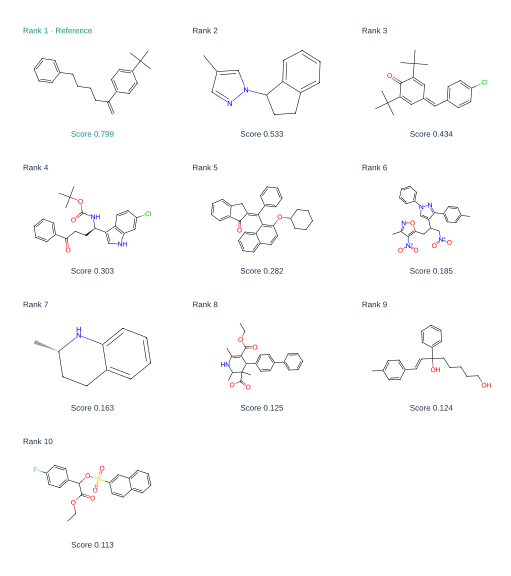

In [4]:
import matplotlib.pyplot as plt
for example_index in range(1):
    figure = render('nmr.retrieval.c.m2s', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## 运行模型

按任务指南配置环境和权重，在 benchmark runner 中选择本任务，即可评估自己的数据集。

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks nmr.retrieval.c.m2s --limit 8 --output results/nmr-retrieval-c-m2s.json
```

[Task](../tasks/nmr-retrieval-c-m2s.md) · [Quick start](../quickstart.md)



## 参考文献

- Yang, L., Yang, Z., Xie, J., Wang, Y., Gao, B., Fu, T., Wei, X., Sun, J., Wu, J., He, C., Li, Y. & Gu, Q. NMRTrans: Structure Elucidation from Experimental NMR Spectra via Set Transformers. arXiv:2602.10158 (2026). [Source](https://arxiv.org/abs/2602.10158)
- Fang, Z., Yang, C., Yu, H., Luo, H., He, H., Xie, J., Yang, Z. & Xia, J. NMRGym: A Comprehensive Benchmark for Nuclear Magnetic Resonance Based Molecular Structure Elucidation. arXiv:2601.15763 (2026). [Source](https://arxiv.org/abs/2601.15763)
- OpenDataLab. WanJuan MolSpectra, version 1.0.3. Experimental molecular spectroscopy dataset. [Source](https://opendatalab.com/)
